In [1]:
pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


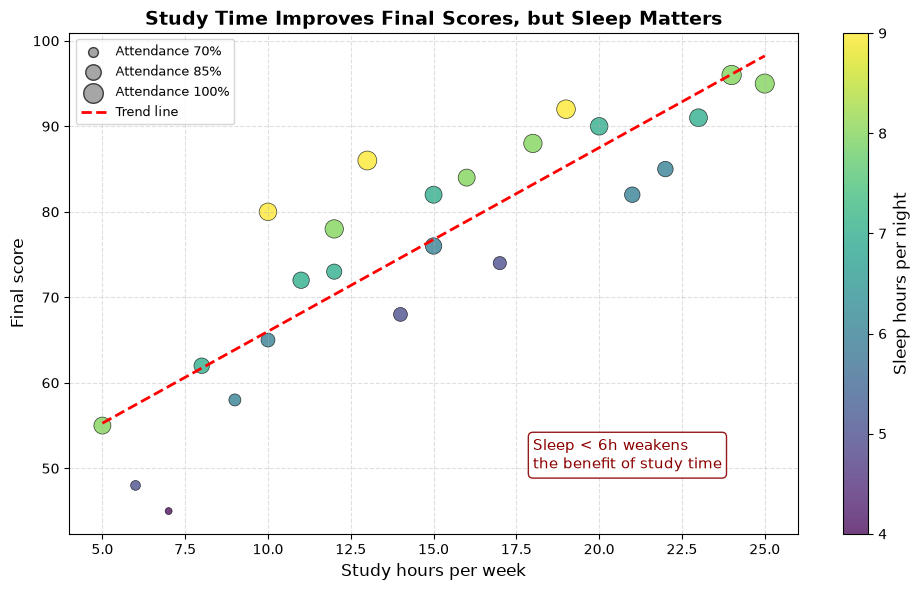

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# 1. 准备数据
# ============================================================
data = {
    "student_id": ["S01","S02","S03","S04","S05","S06","S07","S08","S09","S10",
                   "S11","S12","S13","S14","S15","S16","S17","S18","S19","S20",
                   "S21","S22","S23","S24"],
    "study_hours_per_week": [5,8,10,12,15,18,20,22,25,6,
                             9,11,14,16,19,21,23,7,13,17,
                             24,10,12,15],
    "sleep_hours_per_night": [8,7,6,8,7,8,7,6,8,5,
                              6,7,5,8,9,6,7,4,9,5,
                              8,9,7,6],
    "attendance_rate": [90,85,80,95,90,95,92,85,98,70,
                        75,88,80,90,96,85,93,65,97,78,
                        99,92,84,88],
    "final_score": [55,62,65,78,82,88,90,85,95,48,
                    58,72,68,84,92,82,91,45,86,74,
                    96,80,73,76]
}

df = pd.DataFrame(data)

# 如果你想从 CSV 读取，注释掉上面 data 和 df 部分，
# 取消下面这行注释，并确保 student_scores.csv 在同一文件夹：
# df = pd.read_csv("student_scores.csv")


# ============================================================
# 2. 创建图形
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))

# 散点图：颜色=睡眠，大小=出勤率
scatter = ax.scatter(
    df["study_hours_per_week"],
    df["final_score"],
    c=df["sleep_hours_per_night"],       # 颜色编码睡眠
    s=(df["attendance_rate"] - 60) * 5,  # 大小编码出勤率
    cmap="viridis",                      # 色盲友好色板
    alpha=0.75,
    edgecolors="k",
    linewidths=0.5
)

# 趋势线
z = np.polyfit(df["study_hours_per_week"], df["final_score"], 1)
p = np.poly1d(z)
x_line = np.linspace(
    df["study_hours_per_week"].min(),
    df["study_hours_per_week"].max(),
    100
)
ax.plot(x_line, p(x_line), "r--", linewidth=2)

# 颜色条
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Sleep hours per night", fontsize=12)

# 注释：睡眠不足
ax.text(
    18, 50,
    "Sleep < 6h weakens\nthe benefit of study time",
    fontsize=11,
    color="darkred",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="darkred",
        alpha=0.9
    )
)

# 标题和坐标轴
ax.set_xlabel("Study hours per week", fontsize=12)
ax.set_ylabel("Final score", fontsize=12)
ax.set_title(
    "Study Time Improves Final Scores, but Sleep Matters",
    fontsize=14,
    fontweight="bold"
)
ax.grid(True, linestyle="--", alpha=0.4)

# 自定义图例：点大小表示出勤率，虚线表示趋势线
attendance_legend = [
    plt.scatter([], [], s=(70-60)*5, color="gray", alpha=0.7,
                edgecolors="k", label="Attendance 70%"),
    plt.scatter([], [], s=(85-60)*5, color="gray", alpha=0.7,
                edgecolors="k", label="Attendance 85%"),
    plt.scatter([], [], s=(100-60)*5, color="gray", alpha=0.7,
                edgecolors="k", label="Attendance 100%"),
]
trend_legend = Line2D([0], [0], color="r", linestyle="--",
                      linewidth=2, label="Trend line")

ax.legend(
    handles=attendance_legend + [trend_legend],
    loc="upper left",
    fontsize=9
)

# 保存图片
plt.tight_layout()
plt.savefig("student_scores_visualization.png", dpi=300, bbox_inches="tight")
plt.show()